# Importing libraries

In [58]:
# Import necessary functions and classes from SciPy
from scipy import stats  # Statistical functions
from scipy.stats import median_abs_deviation  # Function to compute the median absolute deviation
from scipy.stats import ttest_ind # Function to perform a t-test

# Import necessary classes and functions from Scikit-Learn for machine learning tasks
from sklearn.compose import ColumnTransformer  # Applies transformers to columns of an array or pandas DataFrame
from sklearn.linear_model import LinearRegression  # Linear regression model
from sklearn.linear_model import LogisticRegression  # Logistic regression model
from sklearn.linear_model import Ridge # Regression model that avoids overfitting
from sklearn.metrics import accuracy_score  # Function to compute the accuracy of a classification model
from sklearn.metrics import classification_report  # Function to compute a text report showing the main classification metrics
from sklearn.metrics import mean_squared_error, r2_score  # Functions to compute regression metrics
from sklearn.model_selection import train_test_split   # Function to split the dataset into training and testing sets
from sklearn.model_selection import cross_val_score # Function to evaluate how well a model generalizes to new data
from sklearn.pipeline import Pipeline  # Tool to group multiple steps in a machine learning model
from sklearn.preprocessing import OneHotEncoder  # Encoder to convert categorical features into one-hot encoded features
from sklearn.preprocessing import StandardScaler  # Normalizes data so it has the same prediction impact
from sklearn.tree import DecisionTreeClassifier  # Decision tree classifier

# Import Matplotlib for plotting and visualizations
import matplotlib.pyplot as plt

# Import NumPy for numerical operations
import numpy as np

# Import pandas for data manipulation and analysis
import pandas as pd

# Import Seaborn for statistical data visualization
import seaborn as sns

# Set seaborn theme to default for plots
sns.set_theme()

# Enable inline plotting for Jupyter notebooks
%matplotlib inline

# Dataset preparation

In [59]:
# Load the property sales data from the Excel file
df = pd.read_excel("2002-2018-property-sales-data.xlsx")

In [60]:
# Export the first 5 rows of the DataFrame
df.head().to_excel('Property sales uncleaned first 5 records.xlsx')

In [61]:
# Display the shape of the DataFrame (number of rows and columns)
df.shape

(34523, 19)

In [62]:
# Display information about the DataFrame including column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34523 entries, 0 to 34522
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PropType      34520 non-null  object 
 1   Taxkey        34523 non-null  int64  
 2   Address       34523 non-null  object 
 3   CondoProject  6656 non-null   object 
 4   District      34523 non-null  int64  
 5   Nbhd          34523 non-null  int64  
 6   Style         34517 non-null  object 
 7   Extwall       24624 non-null  object 
 8   Stories       34523 non-null  float64
 9   Year_Built    34523 non-null  int64  
 10  Nr_of_rms     34523 non-null  int64  
 11  Fin_sqft      34523 non-null  int64  
 12  Units         34523 non-null  int64  
 13  Bdrms         34523 non-null  int64  
 14  Fbath         34523 non-null  int64  
 15  Hbath         34523 non-null  int64  
 16  Lotsize       34523 non-null  int64  
 17  Sale_date     34523 non-null  object 
 18  Sale_price    34523 non-nu

In [63]:
df.head()

,PropType,Taxkey,Address,CondoProject,District,Nbhd,Style,Extwall,Stories,Year_Built,Nr_of_rms,Fin_sqft,Units,Bdrms,Fbath,Hbath,Lotsize,Sale_date,Sale_price
0,Commercial,3230461110,2628 N 6TH ST,NaN,6,6258,Commercial Exempt,NaN,2.00,1880,0,1840,1,0,0,0,12750,2002-01,15900
1,Commercial,3590192000,1363 N PROSPECT AV,NaN,3,6262,Mansions With Commercial Usage,NaN,2.00,1876,0,6377,1,0,0,0,11840,2002-01,850000
2,Commercial,4161194000,617 S 94TH ST,NaN,10,6272,Service Building,NaN,1.00,1954,0,5022,1,0,0,0,9700,2002-01,119000
3,Commercial,1719836000,3624 W SILVER SPRING DR,NaN,1,6218,"Store Bldg - Multi Story (Store & Apt, Store & O",NaN,2.00,1955,0,6420,1,0,0,0,8792,2002-01,210000
4,Commercial,3480290000,3830 W LISBON AV,NaN,15,6254,"Store Bldg - Multi Story (Store & Apt, Store & O",NaN,2.00,1909,0,5956,1,0,0,0,4840,2002-01,48500


# Data cleaning

In [64]:
# Drop duplicate rows from the DataFrame
df.drop_duplicates(inplace=True)

In [65]:
# Drop unnecessary columns from the DataFrame
df.drop(['Taxkey', 'Address', 'CondoProject'], axis=1, inplace=True)

In [66]:
# Fill missing values in the 'Extwall' column with 'Unknown'
df['Extwall'].fillna('Unknown', inplace=True)

In [67]:
# Convert the 'Sale_date' column to datetime format
df['Sale_date'] = pd.to_datetime(df['Sale_date'])

In [68]:
# Convert all text columns to lowercase for consistency
text_columns = df.select_dtypes(include=['object']).columns
df[text_columns] = df[text_columns].apply(lambda x: x.str.lower())

In [69]:
# Drop rows with missing values in 'PropType' and 'Style' columns
df.dropna(subset=['PropType', 'Style'], inplace=True)

In [70]:
# Calculate the median 'Year_Built' for non-vacant land properties
median_year_built = df[(df['PropType'] != 'vacant land') & (df['Year_Built'] > 0)]['Year_Built'].median()

# Replace 'Year_Built' value of 0 with the median year built for non-vacant land properties
df.loc[(df['PropType'] != 'vacant land') & (df['Year_Built'] == 0), 'Year_Built'] = median_year_built

In [71]:
# Filter out properties with a sale price of 0
df = df[df['Sale_price'] > 0]

In [72]:
df["Nr_of_rms"].value_counts()

0     28985
4      2154
5      1536
3       907
6       503
2       108
7        90
1        84
8        48
10        7
9         5
11        2
12        2
Name: Nr_of_rms, dtype: int64

In [73]:
# Remove the Nr_of_rms column
df.drop('Nr_of_rms', axis=1, inplace=True)

# Cleaned dataset overview

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 34431 entries, 0 to 34522
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   PropType    34431 non-null  object        
 1   District    34431 non-null  int64         
 2   Nbhd        34431 non-null  int64         
 3   Style       34431 non-null  object        
 4   Extwall     34431 non-null  object        
 5   Stories     34431 non-null  float64       
 6   Year_Built  34431 non-null  int64         
 7   Fin_sqft    34431 non-null  int64         
 8   Units       34431 non-null  int64         
 9   Bdrms       34431 non-null  int64         
 10  Fbath       34431 non-null  int64         
 11  Hbath       34431 non-null  int64         
 12  Lotsize     34431 non-null  int64         
 13  Sale_date   34431 non-null  datetime64[ns]
 14  Sale_price  34431 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(10), object(3)
memory usage: 4

In [75]:
# Export the the cleaned DataFrame to Excel
df.to_excel('Property sales cleaned dataset.xlsx', index=False)

In [76]:
# Generate summary statistics for the DataFrame and save to an Excel file
df.describe(include="all").to_excel("Property sales description.xlsx")

C:\Users\Cris\anaconda3\envs\data_science\lib\site-packages\ipykernel_launcher.py:2: FutureWarning: Treating datetime data as categorical rather than numeric in `.describe` is deprecated and will be removed in a future version of pandas. Specify `datetime_is_numeric=True` to silence this warning and adopt the future behavior now.
  


# Dataframe optimization

In [77]:
# Define a list of columns that should be treated as integers
integer_cols = ['District', 'Nbhd', 'Fin_sqft', 'Units', 'Bdrms', 'Fbath', 'Hbath', 'Lotsize', 'Year_Built', 
                'Sale_price']

# Convert the specified columns to integer type, downcasting to the smallest possible integer type
df[integer_cols] = df[integer_cols].apply(pd.to_numeric, downcast='integer')

# Define a list of columns that should be treated as categorical variables
object_cols = ['PropType', 'Style', 'Extwall']

# Convert the specified columns to categorical data type
df[object_cols] = df[object_cols].astype('category')

# Define a list of columns that should be treated as float type
float_cols = ['Stories']

# Convert the specified columns to float type, using 32-bit precision
df[float_cols] = df[float_cols].astype('float32')

# Display information about the DataFrame, including column data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 34431 entries, 0 to 34522
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   PropType    34431 non-null  category      
 1   District    34431 non-null  int8          
 2   Nbhd        34431 non-null  int16         
 3   Style       34431 non-null  category      
 4   Extwall     34431 non-null  category      
 5   Stories     34431 non-null  float32       
 6   Year_Built  34431 non-null  int16         
 7   Fin_sqft    34431 non-null  int32         
 8   Units       34431 non-null  int8          
 9   Bdrms       34431 non-null  int16         
 10  Fbath       34431 non-null  int8          
 11  Hbath       34431 non-null  int8          
 12  Lotsize     34431 non-null  int32         
 13  Sale_date   34431 non-null  datetime64[ns]
 14  Sale_price  34431 non-null  int32         
dtypes: category(3), datetime64[ns](1), float32(1), int16(3), int32(3), int

# Data sampling

In [78]:
# Sample 20% of the data, using a fixed random state for reproducibility
sample_df = df.sample(frac=0.2, random_state=1)

In [79]:
# Display the shape of the sampled DataFrame (number of rows and columns)
sample_df.shape

(6886, 15)

In [80]:
# Save the sample DataFrame to an Excel file
sample_df.to_excel('Property sales dataset cleaned sample.xlsx', index=False)

# Visualizations

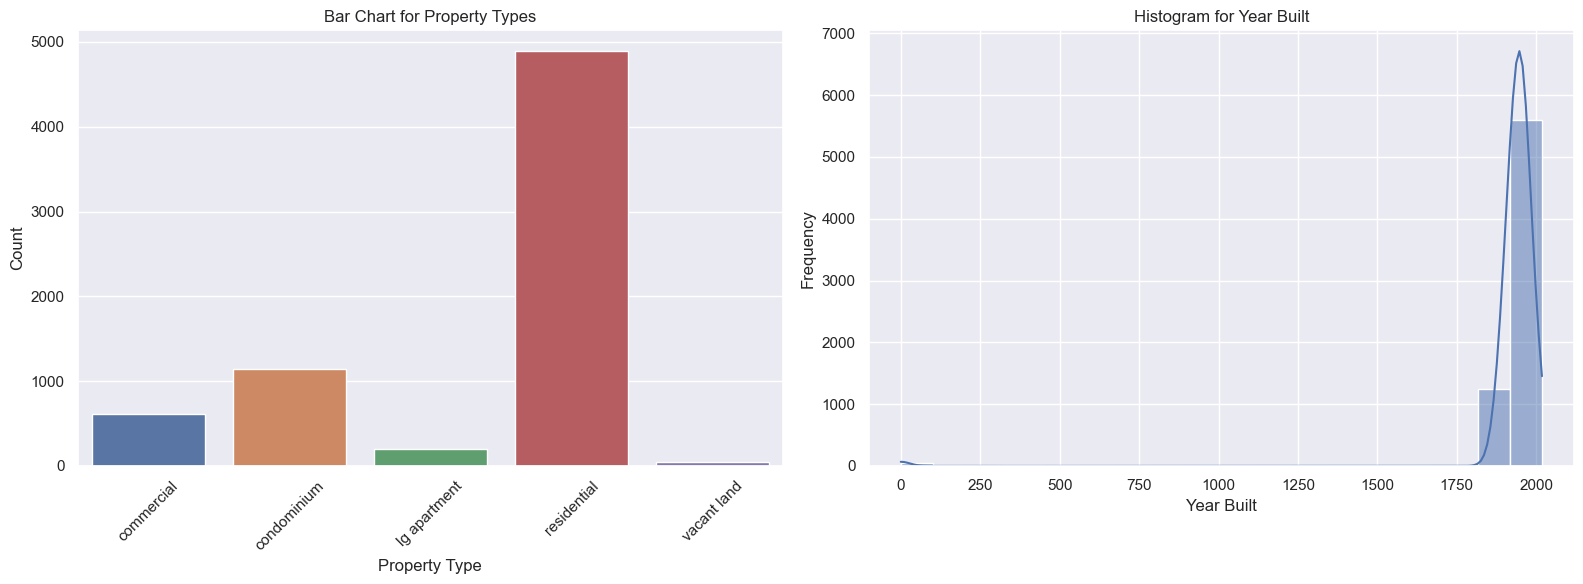

In [81]:
# Create a figure with two subplots, arranged in one row and two columns
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot a bar chart of the property types in the sample DataFrame
sns.countplot(x=sample_df['PropType'], ax=axes[0])
axes[0].set_title('Bar Chart for Property Types')
axes[0].set_xlabel('Property Type')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45) # Rotate x-axis labels for better readability

# Plot a histogram of the year built values in the sample DataFrame
sns.histplot(sample_df['Year_Built'], ax=axes[1], bins=20, kde=True)
axes[1].set_title('Histogram for Year Built')
axes[1].set_xlabel('Year Built')
axes[1].set_ylabel('Frequency')

# Adjust layout to prevent overlap
plt.tight_layout()

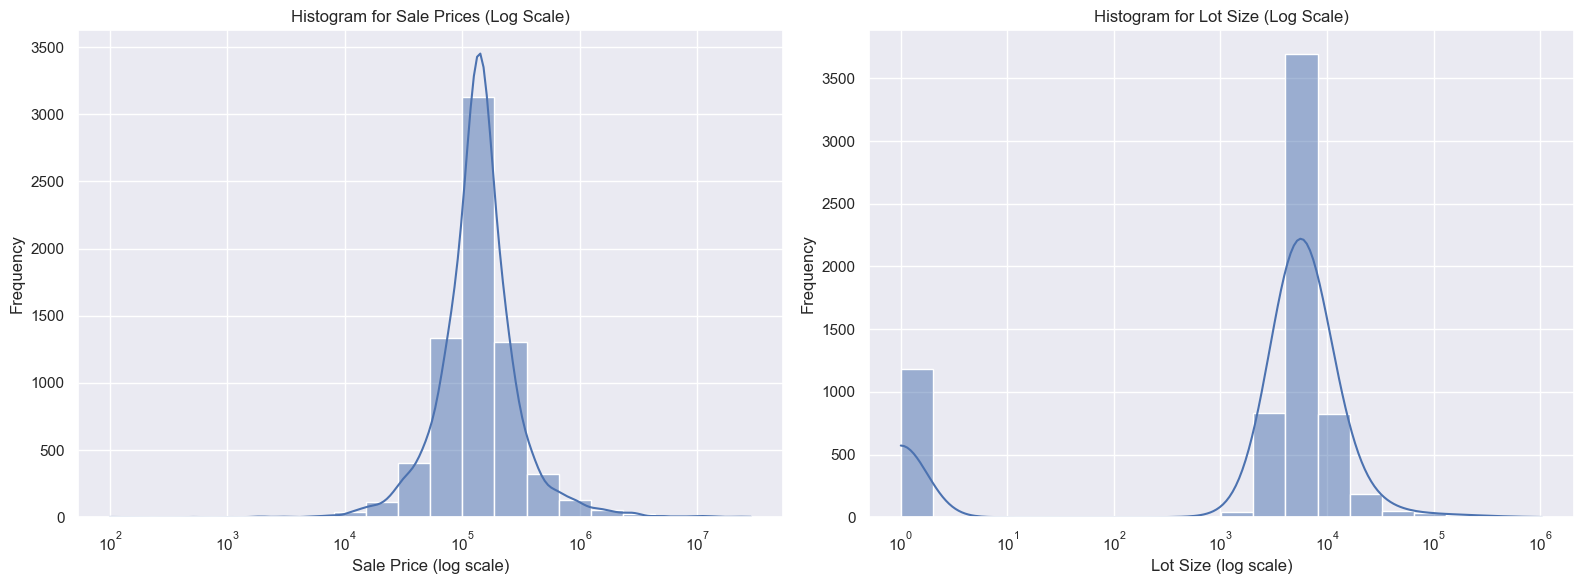

In [82]:
# Create a figure with two subplots, arranged in one row and two columns
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot a histogram of sale prices, using a log scale for better visualization of skewed data
sns.histplot(sample_df['Sale_price'], bins=20, kde=True, log_scale=True, ax=axes[0])
axes[0].set_title('Histogram for Sale Prices (Log Scale)')
axes[0].set_xlabel('Sale Price (log scale)')
axes[0].set_ylabel('Frequency')

# Add 1 to the lot size to avoid issues with log scale (log(0) is undefined)
sample_df['Adjusted_Lotsize'] = sample_df['Lotsize'] + 1
# Plot a histogram of the adjusted lot size, using a log scale
sns.histplot(sample_df['Adjusted_Lotsize'], bins=20, kde=True, log_scale=True, ax=axes[1])
axes[1].set_title('Histogram for Lot Size (Log Scale)')
axes[1].set_xlabel('Lot Size (log scale)')
axes[1].set_ylabel('Frequency')

# Adjust layout to prevent overlap
plt.tight_layout()

In [83]:
# Remove the 'Adjusted_Lotsize' column from the sample DataFrame
sample_df.drop("Adjusted_Lotsize",inplace=True,axis=1)

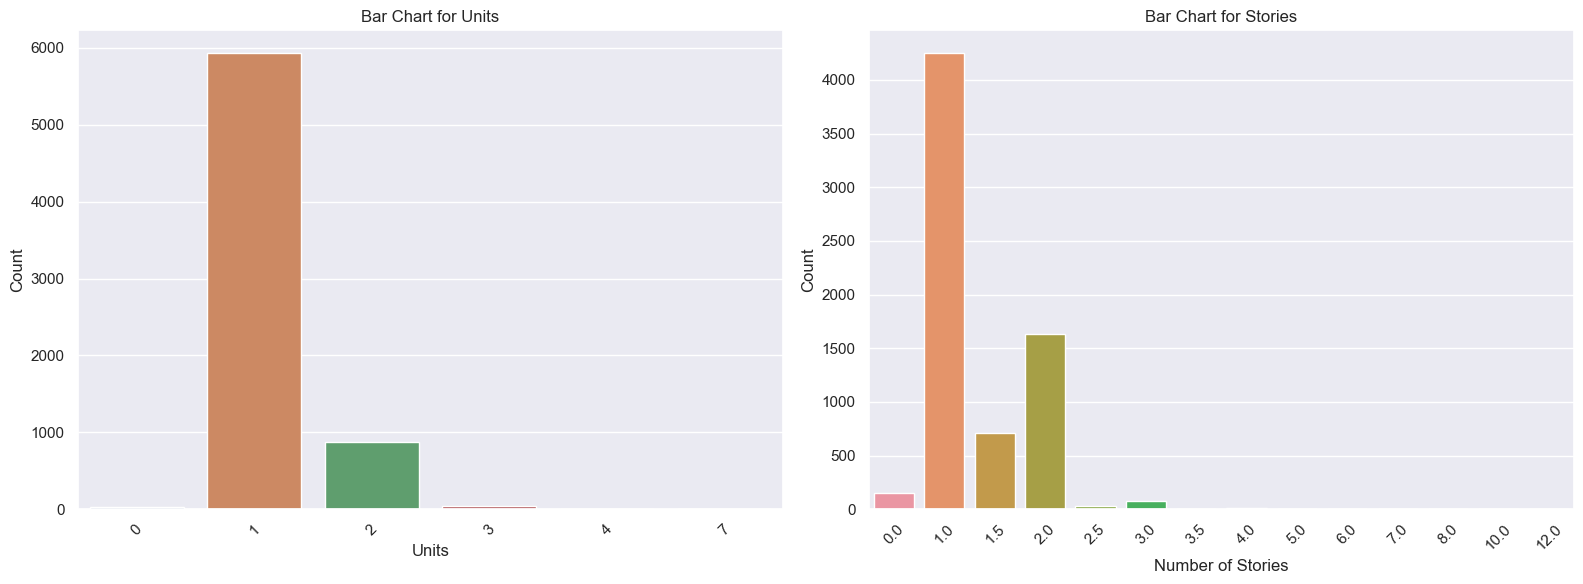

In [84]:
# Create a figure with two subplots, arranged in one row and two columns
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot a bar chart of the number of units in the sample DataFrame
sns.countplot(x=sample_df['Units'], ax=axes[0])
axes[0].set_title('Bar Chart for Units')
axes[0].set_xlabel('Units')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45) # Rotate x-axis labels for better readability

# Plot a bar chart of the number of stories in the sample DataFrame
sns.countplot(x=sample_df['Stories'], ax=axes[1])
axes[1].set_title('Bar Chart for Stories')
axes[1].set_xlabel('Number of Stories')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45) # Rotate x-axis labels for better readability

# Adjust layout to prevent overlap
plt.tight_layout()

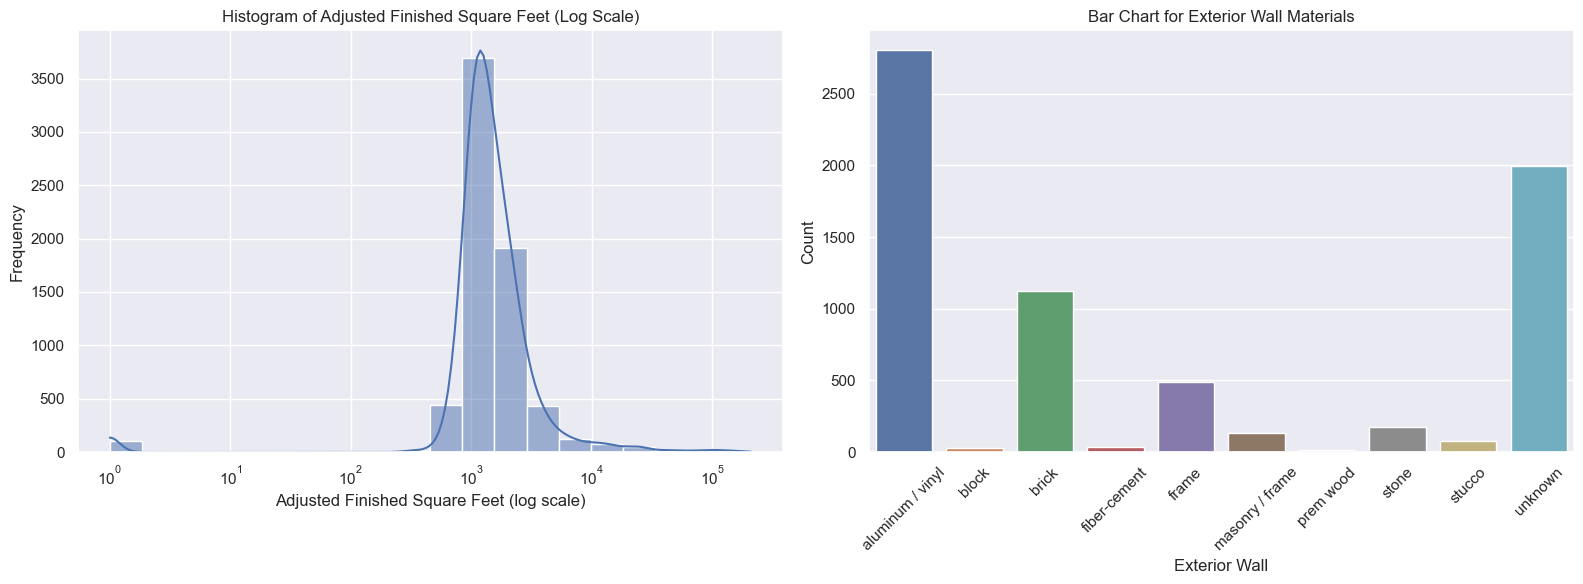

In [85]:
# Add 1 to the final square footage to avoid issues with log scale (log(0) is undefined)
sample_df['Adjusted_Fin_sqft'] = sample_df['Fin_sqft'] + 1

# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot a histogram of 'Adjusted_Fin_sqft' with a logarithmic scale
sns.histplot(sample_df['Adjusted_Fin_sqft'], bins=20, kde=True, log_scale=True, ax=axes[0])
axes[0].set_title('Histogram of Adjusted Finished Square Feet (Log Scale)')
axes[0].set_xlabel('Adjusted Finished Square Feet (log scale)')
axes[0].set_ylabel('Frequency')

# Plot a bar chart of the exterior wall materials in the sample DataFrame
sns.countplot(x=sample_df['Extwall'], ax=axes[1])
axes[1].set_title('Bar Chart for Exterior Wall Materials') # Rotate x-axis labels for better readability
axes[1].set_xlabel('Exterior Wall')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

# Adjust layout to prevent overlap
plt.tight_layout()

In [86]:
# Remove the 'Adjusted_Fin_sqft' column from the DataFrame
sample_df.drop("Adjusted_Fin_sqft",inplace=True,axis=1)

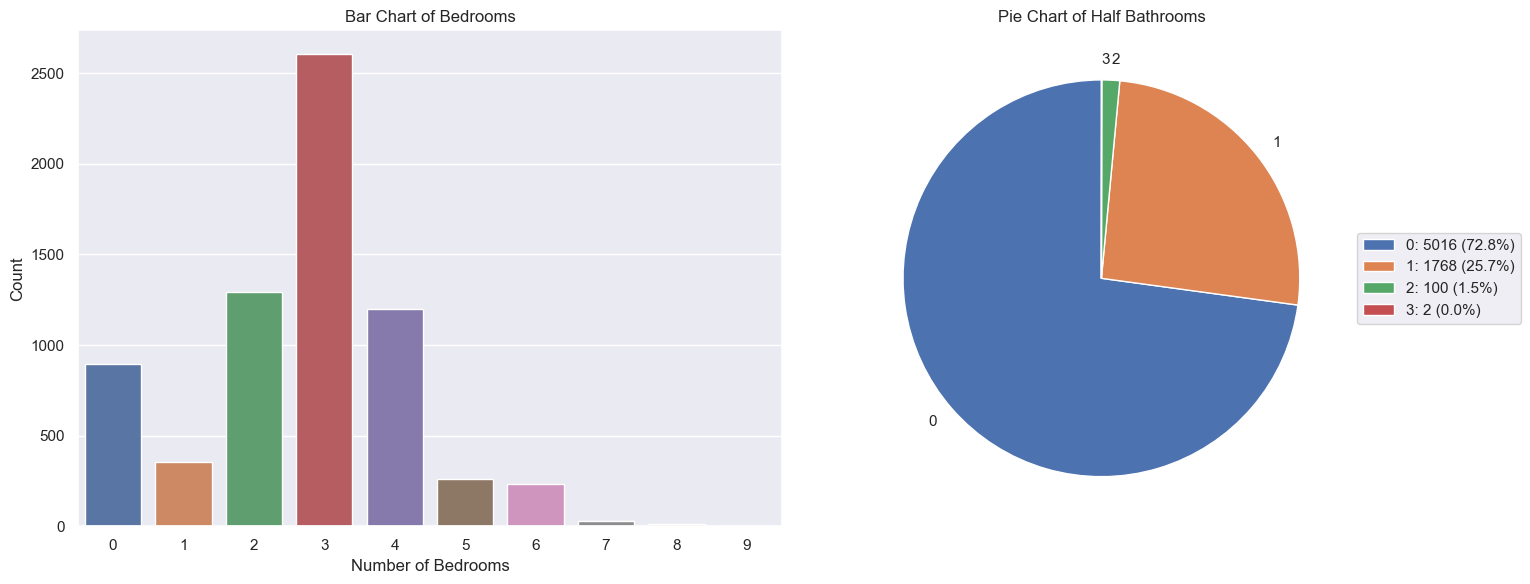

In [87]:
# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot a bar chart of the number of bedrooms
sns.countplot(x=sample_df['Bdrms'], ax=axes[0])
axes[0].set_title('Bar Chart of Bedrooms')
axes[0].set_xlabel('Number of Bedrooms')
axes[0].set_ylabel('Count')

# Plot a pie chart of half bathrooms counts
hbath_counts = sample_df['Hbath'].value_counts()
wedges, texts = axes[1].pie(hbath_counts, labels=hbath_counts.index, startangle=90)
axes[1].set_title('Pie Chart of Half Bathrooms')

# Create a legend with percentages and values
legend_labels = [f'{label}: {count} ({pct:.1f}%)' for label, count, pct in zip(hbath_counts.index, hbath_counts, 
                                                                               100*hbath_counts/hbath_counts.sum())]
axes[1].legend(wedges, legend_labels, loc='center left', bbox_to_anchor=(1, 0.5))

# Adjust layout to prevent overlap
plt.tight_layout()

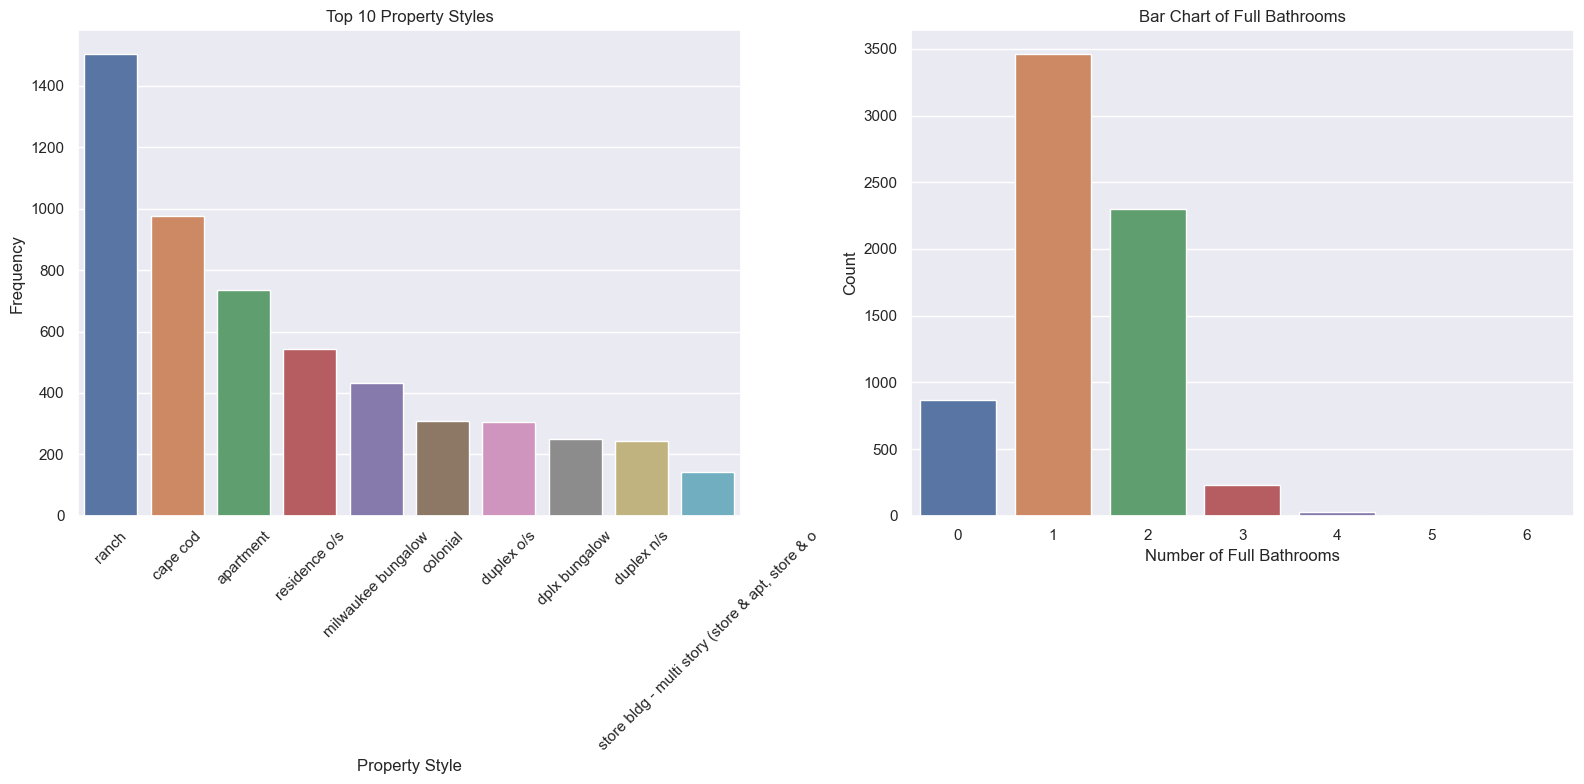

In [88]:
# Identify the top 10 most common property styles
top_styles = sample_df['Style'].value_counts().head(10)

# Filter the DataFrame to include only the top 10 property styles
top_styles_df = sample_df[sample_df['Style'].isin(top_styles.index)]

# Create a new figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Plot a bar chart of the top 10 property styles in the first subplot
sns.countplot(data=top_styles_df, x='Style', order=top_styles.index, ax=axes[0])
axes[0].set_title('Top 10 Property Styles')
axes[0].set_xlabel('Property Style')
axes[0].set_ylabel('Frequency')
axes[0].tick_params(axis='x', rotation=45)  # Rotate x-axis labels for better readability

# Plot a bar chart of the number of full bathrooms in the second subplot
sns.countplot(x=sample_df['Fbath'], ax=axes[1])
axes[1].set_title('Bar Chart of Full Bathrooms')
axes[1].set_xlabel('Number of Full Bathrooms')
axes[1].set_ylabel('Count')

# Adjust layout to prevent overlap
plt.tight_layout()

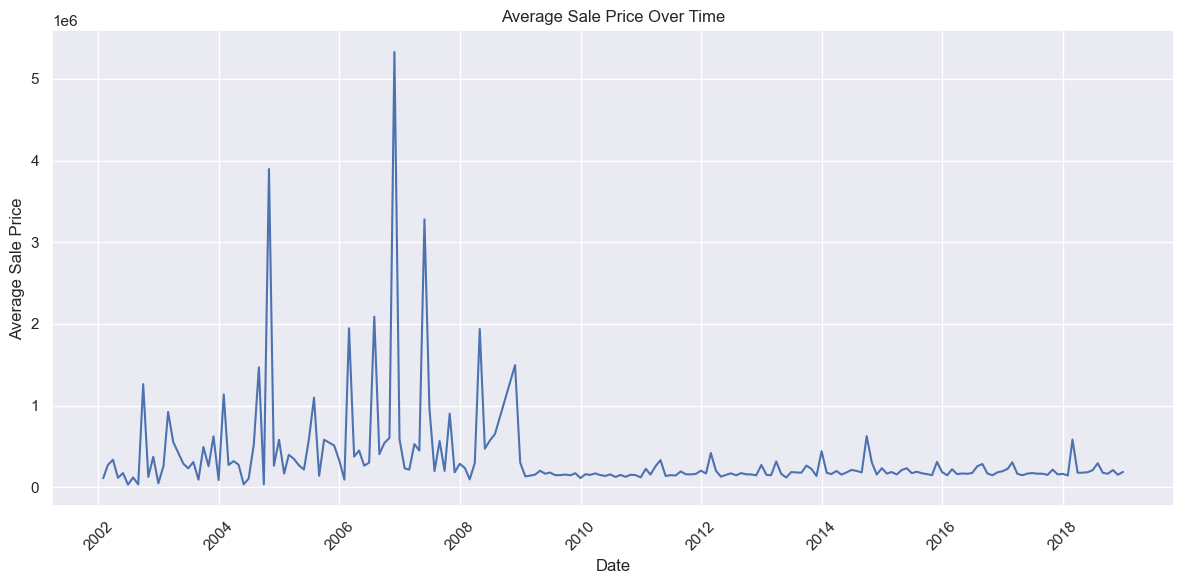

In [89]:
# Resample the data to get the monthly average sale price
monthly_data = sample_df.resample('M', on='Sale_date').mean()

# Create a figure for the line plot of average sale price over time
plt.figure(figsize=(12, 6))

# Plot the average sale price over time
sns.lineplot(data=monthly_data, x=monthly_data.index, y='Sale_price')
plt.title('Average Sale Price Over Time')
plt.xlabel('Date')
plt.ylabel('Average Sale Price')
plt.xticks(rotation=45)
plt.tight_layout()

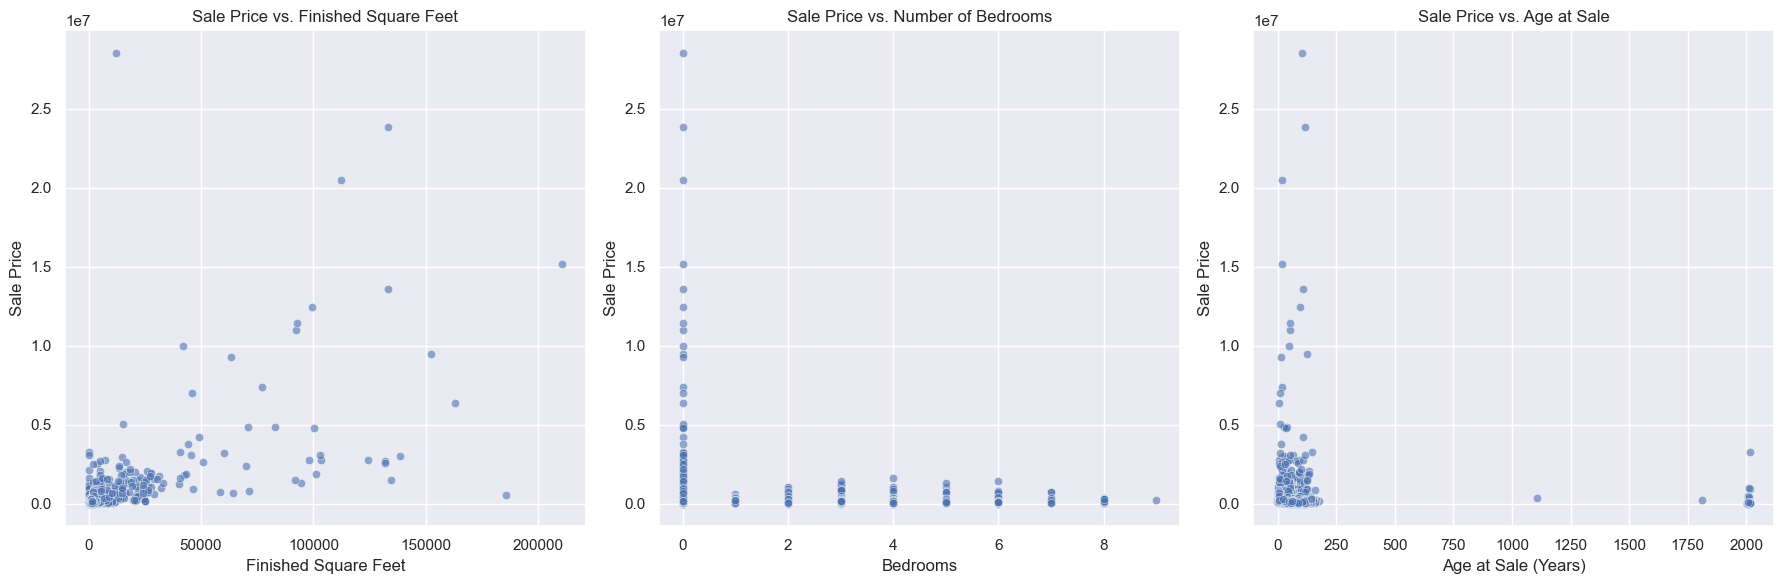

In [90]:
# Calculate the age of the property at the time of sale
sample_df['Age_at_sale'] = sample_df['Sale_date'].dt.year - sample_df['Year_Built']

# Create a figure with three subplots side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot a scatter plot of sale price vs. finished square feet
sns.scatterplot(ax=axes[0], x='Fin_sqft', y='Sale_price', data=sample_df, alpha=0.6)
axes[0].set_title('Sale Price vs. Finished Square Feet')
axes[0].set_xlabel('Finished Square Feet')
axes[0].set_ylabel('Sale Price')

# Plot a scatter plot of sale price vs. number of bedrooms
sns.scatterplot(ax=axes[1], x='Bdrms', y='Sale_price', data=sample_df, alpha=0.6)
axes[1].set_title('Sale Price vs. Number of Bedrooms')
axes[1].set_xlabel('Bedrooms')
axes[1].set_ylabel('Sale Price')

# Plot a scatter plot of sale price vs. age at sale
sns.scatterplot(ax=axes[2], x='Age_at_sale', y='Sale_price', data=sample_df, alpha=0.6)
axes[2].set_title('Sale Price vs. Age at Sale')
axes[2].set_xlabel('Age at Sale (Years)')
axes[2].set_ylabel('Sale Price')


# Adjust layout to prevent overlap
plt.tight_layout()

In [91]:
# Drop the 'Age_at_sale' column from the sample_df DataFrame
sample_df.drop("Age_at_sale",inplace=True,axis=1)

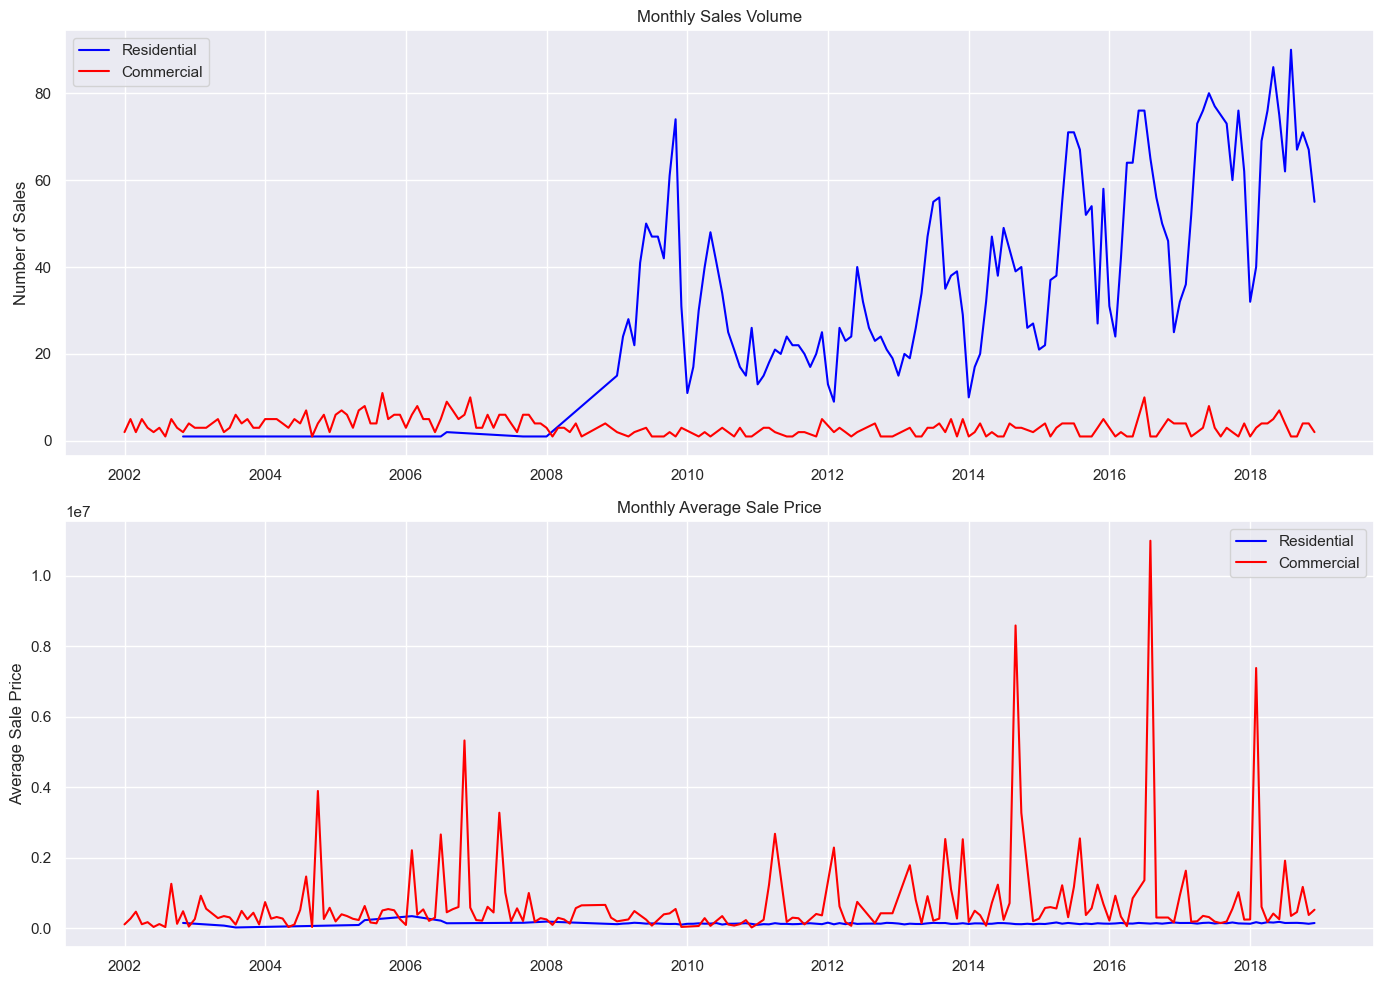

In [92]:
# Filter the sample_df DataFrame to separate residential and commercial properties
residential_data = sample_df[sample_df['PropType'] == 'residential']
commercial_data = sample_df[sample_df['PropType'] == 'commercial']

# Group the residential data by month and count the number of sales per month
res_sales_volume = residential_data.groupby(residential_data['Sale_date'].dt.to_period("M")).size()

# Group the commercial data by month and count the number of sales per month
com_sales_volume = commercial_data.groupby(commercial_data['Sale_date'].dt.to_period("M")).size()

# Calculate the monthly average sale price for residential properties
res_price_trends = residential_data.groupby(residential_data['Sale_date'].dt.to_period("M"))['Sale_price'].mean()

# Calculate the monthly average sale price for commercial properties
com_price_trends = commercial_data.groupby(commercial_data['Sale_date'].dt.to_period("M"))['Sale_price'].mean()

# Create subplots for the sales volume and average sale price trends
fig, ax = plt.subplots(2, 1, figsize=(14, 10))

# Plot the monthly sales volume for residential and commercial properties
ax[0].plot(res_sales_volume.index.to_timestamp(), res_sales_volume, label='Residential', color='blue')
ax[0].plot(com_sales_volume.index.to_timestamp(), com_sales_volume, label='Commercial', color='red')
ax[0].set_title('Monthly Sales Volume')
ax[0].set_ylabel('Number of Sales')
ax[0].legend()

# Plot the monthly average sale price for residential and commercial properties
ax[1].plot(res_price_trends.index.to_timestamp(), res_price_trends, label='Residential', color='blue')
ax[1].plot(com_price_trends.index.to_timestamp(), com_price_trends, label='Commercial', color='red')
ax[1].set_title('Monthly Average Sale Price')
ax[1].set_ylabel('Average Sale Price')
ax[1].legend()

# Adjust layout to prevent overlap
plt.tight_layout()

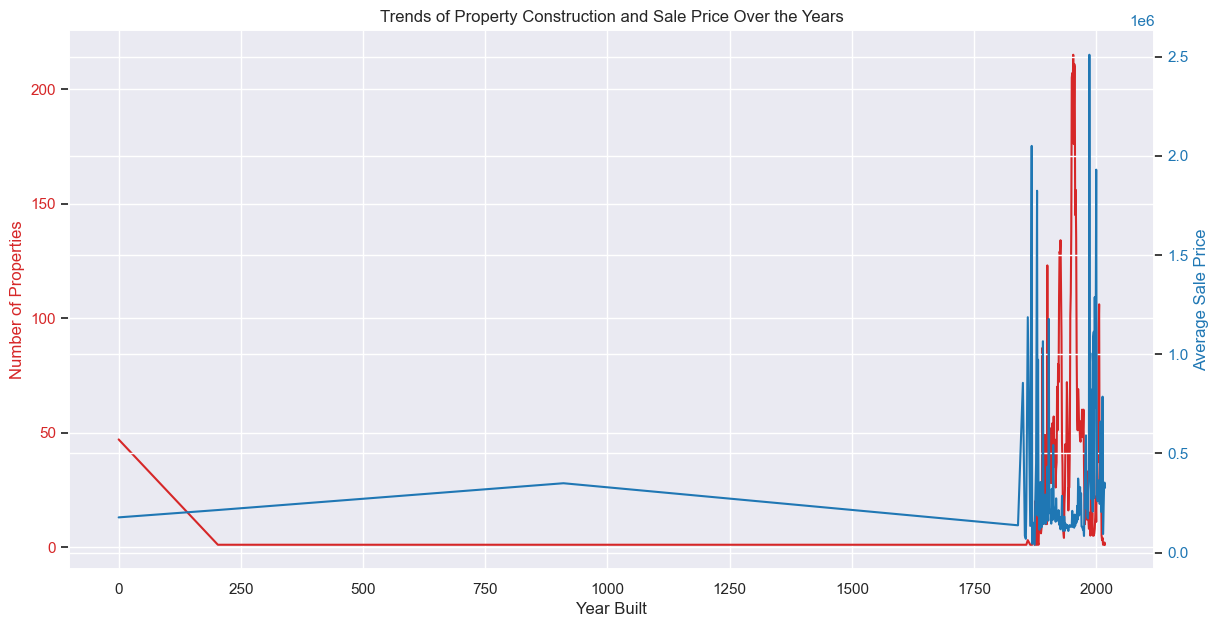

In [93]:
# Aggregate data by year built and calculate number of properties, average lot size, and average sale price
yearly_data = sample_df.groupby('Year_Built').agg(
    Number_of_Properties=pd.NamedAgg(column='PropType', aggfunc='count'),
    Average_Lotsize=pd.NamedAgg(column='Lotsize', aggfunc='mean'),
    Average_Sale_Price=pd.NamedAgg(column='Sale_price', aggfunc='mean')
).reset_index()

# Create a plot for trends of property construction and sale price over the years
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot the number of properties built each year
color = 'tab:red'
ax1.set_xlabel('Year Built')
ax1.set_ylabel('Number of Properties', color=color)
ax1.plot(yearly_data['Year_Built'], yearly_data['Number_of_Properties'], color=color)
ax1.tick_params(axis='y', labelcolor=color)

# Create a second y-axis for the average sale price
ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Average Sale Price', color=color)
ax2.plot(yearly_data['Year_Built'], yearly_data['Average_Sale_Price'], color=color)
ax2.tick_params(axis='y', labelcolor=color)

# Set the title and enable grid
plt.title('Trends of Property Construction and Sale Price Over the Years')
plt.grid(True)

In [94]:
# Set the display format for floating-point numbers, showing 2 decimal places
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Group the data by 'District' and calculate the mean sale price for each district
district_prices = sample_df.groupby('District')['Sale_price'].mean().sort_values()

# Print the average sale prices by district
print("Average Sale Prices by District:")
print(district_prices)

# Group the data by 'Nbhd' (neighborhood) and calculate the mean sale price for each neighborhood
neighborhood_prices = sample_df.groupby('Nbhd')['Sale_price'].mean().sort_values()

# Select the top 10 neighborhoods with the highest average sale prices
top_10_neighborhoods = neighborhood_prices.tail(10)

# Select the bottom 10 neighborhoods with the lowest average sale prices
bottom_10_neighborhoods = neighborhood_prices.head(10)

# Print the top 10 neighborhoods by average sale price
print("\nTop 10 Neighborhoods by Average Sale Price:")
print(top_10_neighborhoods)

# Print the bottom 10 neighborhoods by average sale price
print("\nBottom 10 Neighborhoods by Average Sale Price:")
print(bottom_10_neighborhoods)

Average Sale Prices by District:
District
8    101567.13
1    102886.39
7    107361.80
2    141632.52
11   165893.88
15   169316.24
10   172673.64
9    179385.19
14   187235.35
5    187666.58
13   214311.90
12   268603.96
6    290428.09
3    297449.28
4    539357.20
Name: Sale_price, dtype: float64

Top 10 Neighborhoods by Average Sale Price:
Nbhd
6982    3100000.00
6453    3139420.20
6415    3173127.00
6969    3387500.00
6981    4825000.00
6455    5090000.00
6296    5158000.00
6475    8114474.22
6452   11460000.00
6447   28530000.00
Name: Sale_price, dtype: float64

Bottom 10 Neighborhoods by Average Sale Price:
Nbhd
6702   12000.00
5060   15987.50
5078   19500.00
5160   21000.00
2950   23337.50
5240   25000.00
5080   26357.14
5140   27666.67
2850   28529.41
2960   29000.00
Name: Sale_price, dtype: float64


In [95]:
# Group the data by 'District' and find the most common 'Style' and 'Extwall' for each district
district_style_wall = sample_df.groupby('District').agg({
    'Style': lambda x: x.mode()[0], # Most common style
    'Extwall': lambda x: x.mode()[0] # Most common exterior wall type
})

# Reset the index to turn the group labels into a column
district_style_wall.reset_index(inplace=True)

# Display the resulting DataFrame
district_style_wall

,District,Style,Extwall
0,1,ranch,aluminum / vinyl
1,2,ranch,aluminum / vinyl
2,3,apartment,unknown
3,4,apartment,unknown
4,5,ranch,aluminum / vinyl
5,6,apartment,unknown
6,7,cape cod,aluminum / vinyl
7,8,residence o/s,aluminum / vinyl
8,9,ranch,unknown
9,10,milwaukee bungalow,aluminum / vinyl


# Central tendency measures

In [96]:
# Compute the mean, median, and mode for each column in the sample dataframe
mean_values = sample_df.mean()
median_values = sample_df.median()
mode_values = sample_df.mode().iloc[0]

# Create a new dataframe to store the central tendency statistics
statistics_df = pd.DataFrame({
    'mean': mean_values,
    'median': median_values,
    'mode': mode_values
})

# Transpose the dataframe for better readability
statistics_df = statistics_df.transpose()

# Save the central tendency statistics to an Excel file
statistics_df.to_excel('Property sales routine tendencies.xlsx')

C:\Users\Cris\anaconda3\envs\data_science\lib\site-packages\ipykernel_launcher.py:2: FutureWarning: DataFrame.mean and DataFrame.median with numeric_only=None will include datetime64 and datetime64tz columns in a future version.
  
C:\Users\Cris\anaconda3\envs\data_science\lib\site-packages\ipykernel_launcher.py:2: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  
C:\Users\Cris\anaconda3\envs\data_science\lib\site-packages\ipykernel_launcher.py:3: FutureWarning: DataFrame.mean and DataFrame.median with numeric_only=None will include datetime64 and datetime64tz columns in a future version.
  This is separate from the ipykernel package so we can avoid doing imports until
C:\Users\Cris\anaconda3\envs\data_science\lib\site-packages\ipykernel_launcher.py:3: FutureWarning: Dropping of nuisance columns in DataFrame reductions (w

In [97]:
# Calculate the trimmed mean of 'Sale_price' by excluding the lowest and highest 10% of the data
trimmed_mean_sale_price = stats.trim_mean(sample_df['Sale_price'], 0.1)

# Calculate the trimmed mean of 'Lotsize' by excluding the lowest and highest 10% of the data
trimmed_mean_lotsize = stats.trim_mean(sample_df['Lotsize'], 0.1)

# Calculate the trimmed mean of 'Fin_sqft' by excluding the lowest and highest 10% of the data
trimmed_mean_fin_sqft = stats.trim_mean(sample_df['Fin_sqft'], 0.1)

# Print the trimmed mean values
print("Trimmed Mean of Sale_price:", trimmed_mean_sale_price)
print("Trimmed Mean of Lotsize:", trimmed_mean_lotsize)
print("Trimmed Mean of Fin_sqft:", trimmed_mean_fin_sqft)

Trimmed Mean of Sale_price: 146335.22359346642
Trimmed Mean of Lotsize: 5129.091288566243
Trimmed Mean of Fin_sqft: 1492.719782214156


In [98]:
# Filter the DataFrame to exclude properties with zero finished square footage
filtered_sample_df = sample_df[sample_df['Fin_sqft'] > 0]

# Calculate the weighted mean of 'Sale_price' using 'Fin_sqft' as weights
weighted_mean_sale_price = (sample_df['Sale_price'] * sample_df['Fin_sqft']).sum() / sample_df['Fin_sqft'].sum()

# Print the weighted mean sale price
print("Weighted Mean of Sale_price:", weighted_mean_sale_price)

Weighted Mean of Sale_price: 95422.74916869302


In [99]:
# Extract the year from the 'Sale_date' column and add it as a new column 'Year'
sample_df['Year'] = sample_df['Sale_date'].dt.year

# Calculate the average sale price for each year
yearly_avg_price = sample_df.groupby('Year')['Sale_price'].mean()

# Calculate the yearly growth rates as a percentage change from the previous year
yearly_growth_rates = yearly_avg_price.pct_change().dropna()

# Calculate the geometric mean growth rate
geometric_mean_growth = np.exp(np.mean(np.log(1 + yearly_growth_rates))) - 1

# Display the geometric mean growth rate
print("Geometric mean growth rate:", geometric_mean_growth)

# Remove the 'Year' column from the DataFrame
sample_df.drop("Year",inplace=True,axis=1)

Geometric mean growth rate: -0.02272779659353219


# Measures of dispersion

In [100]:
# Calculate the dispersion measure statistics for the DataFrame
std_deviation = sample_df.std()  # Standard deviation
variance = sample_df.var()       # Variance
range_df = sample_df.max() - sample_df.min()  # Range (max - min)
Q1 = sample_df.quantile(0.25)    # 1st quartile (25th percentile)
Q3 = sample_df.quantile(0.75)    # 3rd quartile (75th percentile)
IQR = Q3 - Q1                    # Interquartile range (IQR)
P90 = sample_df.quantile(0.90)   # 90th percentile
P10 = sample_df.quantile(0.10)   # 10th percentile
IPR = P90 - P10                  # Interpercentile range (90th - 10th percentile)


# Create a DataFrame to hold the dispersion measure statistics
stats_df = pd.DataFrame({
    'Standard Deviation': std_deviation,
    'Variance': variance,
    'Range': range_df,
    'Interquartile Range': IQR,
    'Interpercentile Range (90th - 10th)': IPR
})

# Transpose the DataFrame for better readability
stats_df = stats_df.T

# Save the DataFrame with dispersion measure statistics to an Excel file
stats_df.to_excel('Property sales routine dispersion.xlsx')

C:\Users\Cris\anaconda3\envs\data_science\lib\site-packages\ipykernel_launcher.py:2: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  
C:\Users\Cris\anaconda3\envs\data_science\lib\site-packages\ipykernel_launcher.py:3: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  This is separate from the ipykernel package so we can avoid doing imports until
C:\Users\Cris\anaconda3\envs\data_science\lib\site-packages\ipykernel_launcher.py:4: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  after removing t

In [101]:
# Calculate the Mean Absolute Deviation (MAD) of 'Fin_sqft' for each property type
mad_fin_sqft = sample_df.groupby('PropType')['Fin_sqft'].mad()

# Display the mean absolute deviation in square footage for all property types
mad_fin_sqft

PropType
commercial     12042.68
condominium      388.32
lg apartment    6575.98
residential      455.26
vacant land        0.00
Name: Fin_sqft, dtype: float64

In [102]:
# Calculate the Median Absolute Deviation (MAD) for 'Sale_price', 'Lotsize', and 'Fin_sqft'
mad_sale_price = median_abs_deviation(sample_df['Sale_price'])
mad_lotsize = median_abs_deviation(sample_df['Lotsize'])
mad_squarefeet = median_abs_deviation(sample_df['Fin_sqft'])

# Display the MAD values for 'Sale_price', 'Lotsize', and 'Fin_sqft'
mad_sale_price, mad_lotsize, mad_squarefeet

(48000.0, 1640.0, 360.0)

In [103]:
# Calculate the Interquartile Range (IQR) for 'Sale_price', 'Fin_sqft', and 'Lotsize'
iqr_values = sample_df[['Sale_price', 'Fin_sqft', 'Lotsize']].quantile([0.25, 0.75])
iqr_sale_price = iqr_values.loc[0.75, 'Sale_price'] - iqr_values.loc[0.25, 'Sale_price']
iqr_fin_sqft = iqr_values.loc[0.75, 'Fin_sqft'] - iqr_values.loc[0.25, 'Fin_sqft']
iqr_lotsize = iqr_values.loc[0.75, 'Lotsize'] - iqr_values.loc[0.25, 'Lotsize']

# Calculate the Semi-Interquartile Range (SIQR) for 'Sale_price', 'Fin_sqft', and 'Lotsize'
siqr_sale_price = iqr_sale_price / 2
siqr_fin_sqft = iqr_fin_sqft / 2
siqr_lotsize = iqr_lotsize / 2

# Display the Semi-Interquartile Range values for 'Sale_price', 'Fin_sqft', and 'Lotsize'
siqr_sale_price, siqr_fin_sqft, siqr_lotsize

(49750.0, 444.875, 1800.0)

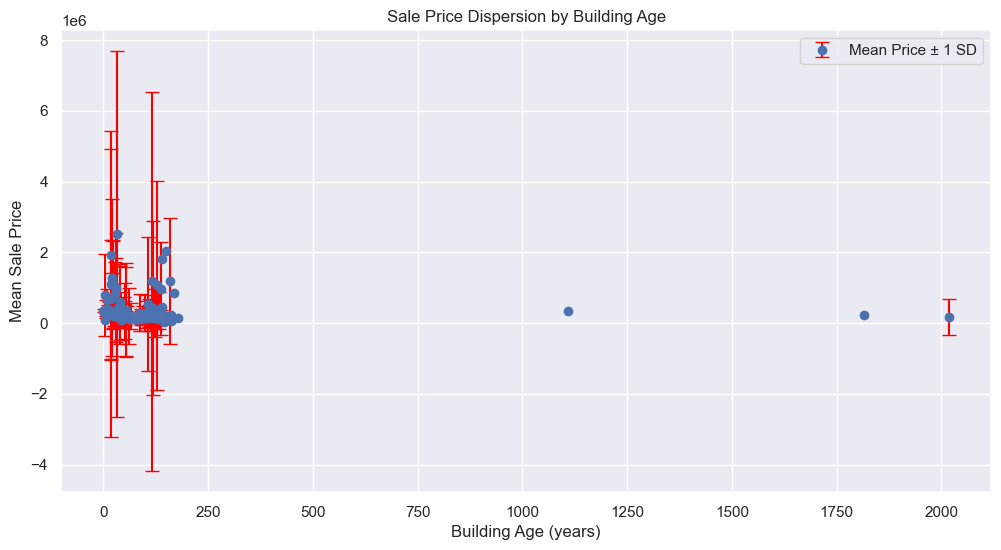

In [104]:
# Get the most recent year in the 'Sale_date' column
current_year = sample_df['Sale_date'].max().year

# Calculate the age of each building and store it in a new column 'Building_Age'
sample_df['Building_Age'] = current_year - sample_df['Year_Built']

# Group by 'Building_Age' and calculate the mean and standard deviation of 'Sale_price'
age_price_stats = sample_df.groupby('Building_Age')['Sale_price'].agg(['mean', 'std']).reset_index()

# Plot the mean sale price with error bars representing one standard deviation
plt.figure(figsize=(12, 6))
plt.errorbar(age_price_stats['Building_Age'], age_price_stats['mean'], yerr=age_price_stats['std'], fmt='o', ecolor='red', 
             capsize=5, label='Mean Price ± 1 SD')
plt.title('Sale Price Dispersion by Building Age')
plt.xlabel('Building Age (years)')
plt.ylabel('Mean Sale Price')
plt.grid(True)
plt.legend()

# Remove the 'Building_Age' column from the DataFrame
sample_df.drop("Building_Age",inplace=True,axis=1)

In [105]:
# Define a function to calculate the Gini coefficient, which measures inequality
def gini(x):
    sorted_x = np.sort(x) # Sort the values in ascending order
    n = len(x) # Get the number of values
    cumulative_sum_x = np.cumsum(sorted_x, dtype=float) # Calculate the cumulative sum of the sorted values
    mean_x = cumulative_sum_x[-1] / n # Calculate the mean of the values
    
    # Calculate the Gini coefficient using the formula
    gini = (n + 1 - 2 * np.sum(cumulative_sum_x) / cumulative_sum_x[-1]) / n
    return gini

# Apply the Gini function to 'Sale_price' for each 'District' and reset the index
gini_by_district = sample_df.groupby('District')['Sale_price'].apply(gini).reset_index()
gini_by_district

,District,Sale_price
0,1,0.46
1,2,0.46
2,3,0.38
3,4,0.62
4,5,0.44
5,6,0.67
6,7,0.42
7,8,0.28
8,9,0.54
9,10,0.36


# Probability distribution operations

In [106]:
# Calculate the number of properties with different bedroom counts
bdrms_counts = sample_df['Bdrms'].value_counts().sort_index()

# Calculate the total number of properties
total_properties = sample_df['Bdrms'].count()

# Calculate the probability mass function (PMF) for the number of bedrooms
pmf_bdrms = bdrms_counts / total_properties

# Create a DataFrame to store the PMF data
pmf_data_bdrms = pd.DataFrame({'Bdrms': pmf_bdrms.index, 'Probability': pmf_bdrms.values})

# Display the PMF data
pmf_data_bdrms

,Bdrms,Probability
0,0,0.13
1,1,0.05
2,2,0.19
3,3,0.38
4,4,0.17
5,5,0.04
6,6,0.03
7,7,0.00
8,8,0.00
9,9,0.00


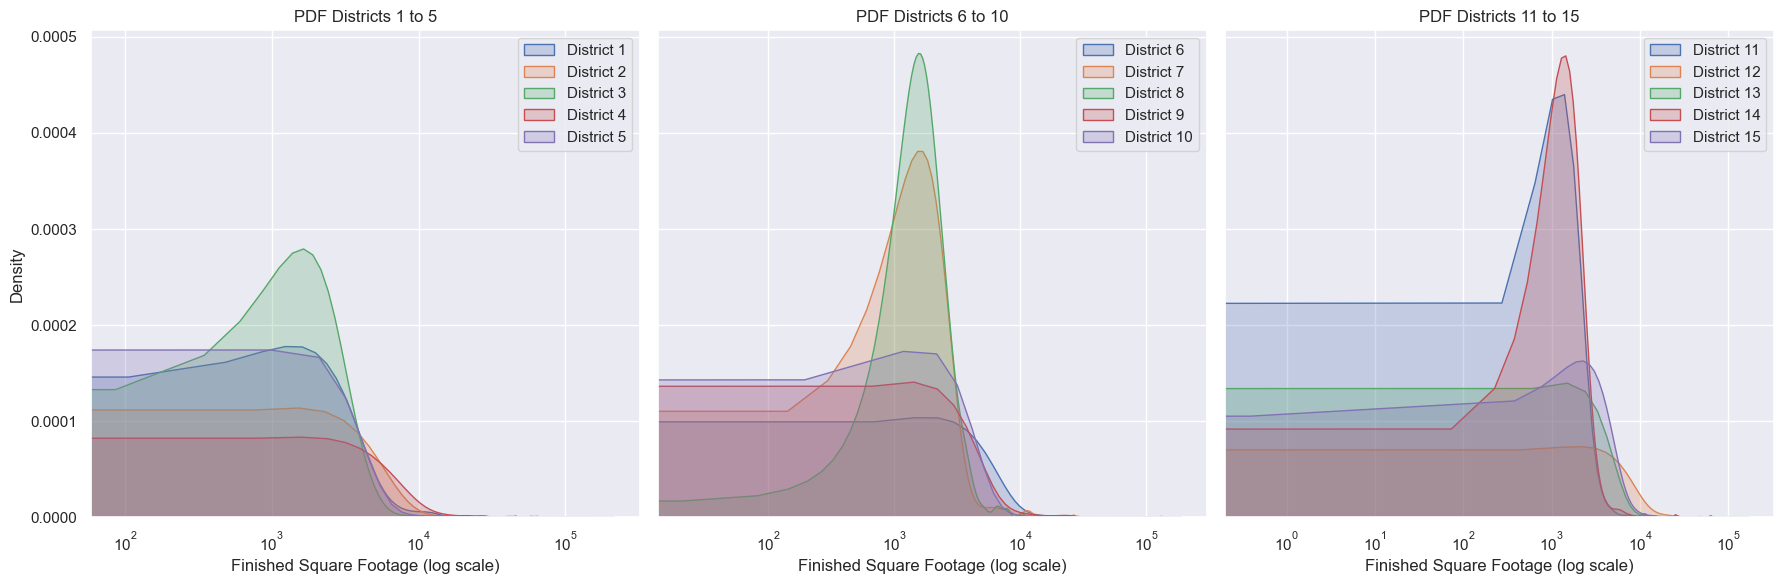

In [107]:
# Filter out properties with finished square footage greater than 0
filtered_fin_sqft = sample_df[sample_df['Fin_sqft'] > 0]

# Get unique districts and sort them
unique_districts = sorted(filtered_fin_sqft['District'].unique())

# Setting up the figure for 3 subplots arranged in 1 row and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)  # 1 row, 3 columns

# Divide districts into three groups for each subplot
district_groups = [unique_districts[i:i + 5] for i in range(0, len(unique_districts), 5)]

# Loop through each group of districts and plot their KDE (Kernel Density Estimation)
for i, group in enumerate(district_groups):
    ax = axes[i]
    for district in group:
        # Select the data for the current district
        district_data = filtered_fin_sqft[filtered_fin_sqft['District'] == district]['Fin_sqft']
        # Plot the KDE for each district on the respective subplot
        sns.kdeplot(district_data, ax=ax, label=f'District {district}', fill=True)
    ax.set_title(f'PDF Districts {group[0]} to {group[-1]}') # Set title for each subplot
    ax.set_xlabel('Finished Square Footage (log scale)') # Set x-axis label
    ax.set_xscale('log') # Set x-axis scale to log
    ax.legend() # Add legend to each subplot

# Set a common y label
axes[0].set_ylabel('Density')

# Adjust the layout to prevent overlap
plt.tight_layout()

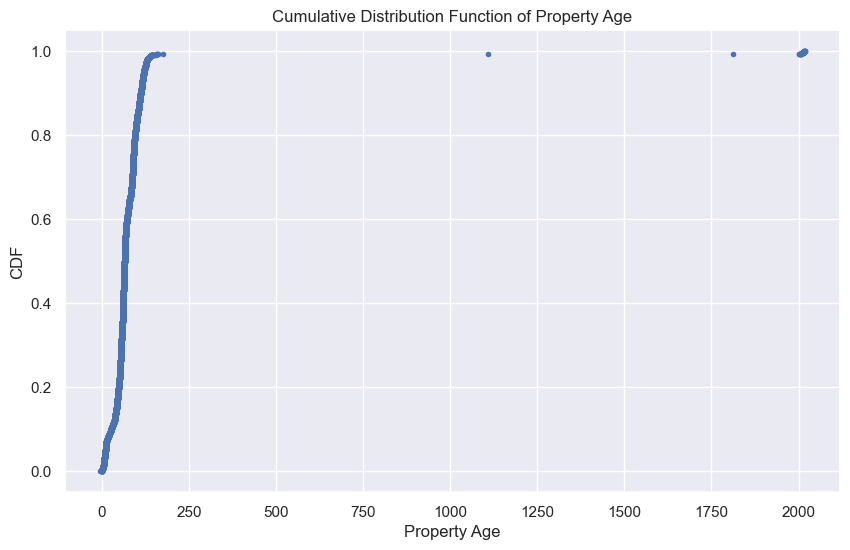

In [108]:
# Calculate property age at the time of sale
sample_df['Year_Sold'] = sample_df['Sale_date'].dt.year
sample_df['Property_Age'] = sample_df['Year_Sold'] - sample_df['Year_Built']

# Sort the property ages
property_age = sample_df['Property_Age'].sort_values()

# Calculate CDF values
cdf_values = np.arange(1, len(property_age) + 1) / len(property_age)

# Plot the CDF
plt.figure(figsize=(10, 6))
plt.plot(property_age, cdf_values, marker='.', linestyle='none')
plt.xlabel('Property Age')
plt.ylabel('CDF')
plt.title('Cumulative Distribution Function of Property Age')
plt.grid(True)

# Remove the created columns
sample_df.drop(['Year_Sold', 'Property_Age'], axis=1, inplace=True)

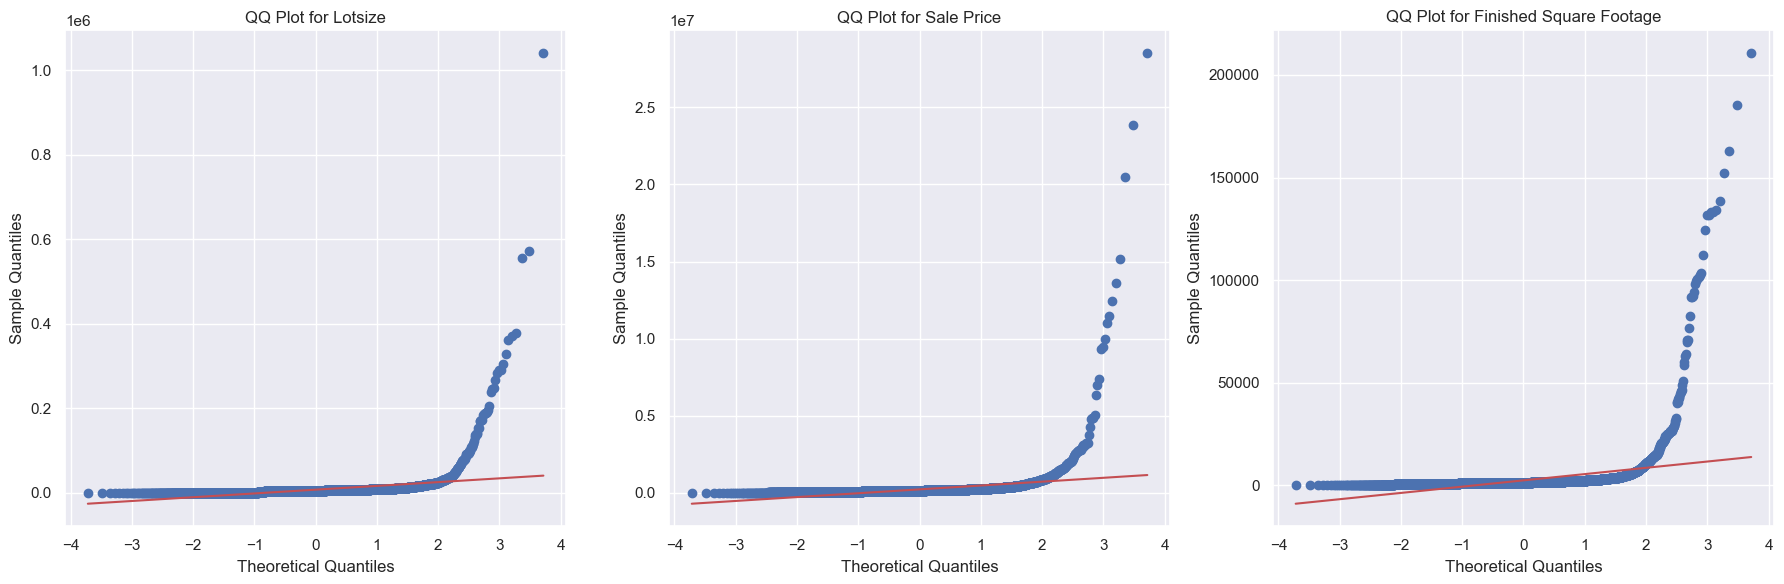

In [109]:
# Create a figure with three subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# QQ Plot for Lotsize
stats.probplot(sample_df['Lotsize'], dist="norm", plot=axes[0])
axes[0].set_title('QQ Plot for Lotsize')
axes[0].set_xlabel('Theoretical Quantiles')
axes[0].set_ylabel('Sample Quantiles')

# QQ Plot for Sale Price
stats.probplot(sample_df['Sale_price'], dist="norm", plot=axes[1])
axes[1].set_title('QQ Plot for Sale Price')
axes[1].set_xlabel('Theoretical Quantiles')
axes[1].set_ylabel('Sample Quantiles')

# QQ Plot for Finished Square Footage
stats.probplot(sample_df['Fin_sqft'], dist="norm", plot=axes[2])
axes[2].set_title('QQ Plot for Finished Square Footage')
axes[2].set_xlabel('Theoretical Quantiles')
axes[2].set_ylabel('Sample Quantiles')

# Adjust the layout to prevent overlap
plt.tight_layout()

In [110]:
# Filter the dataset for the two styles
ranch_prices = sample_df[sample_df['Style'] == 'ranch']['Sale_price']
cape_cod_prices = sample_df[sample_df['Style'] == 'cape cod']['Sale_price']

# Perform a two-sample t-test
t_stat, p_value = ttest_ind(ranch_prices, cape_cod_prices, equal_var=False)

# Print the t-statistic and p-value
print("T-statistic:", t_stat)
print("P-value:", p_value)

# Check if the p-value is less than 0.05 for statistical significance
if p_value < 0.05:
    print("There is a statistically significant difference between the two groups.")
else:
    print("There is no statistically significant difference between the two groups.")

T-statistic: -3.327850417560852
P-value: 0.0008910539191228936
There is a statistically significant difference between the two groups.


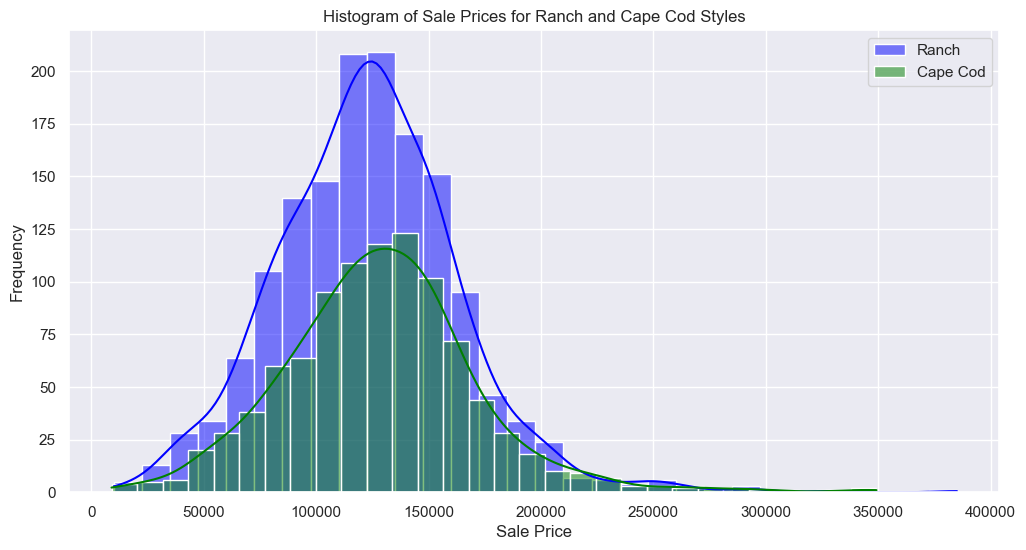

In [111]:
# Filter data for 'ranch' and 'cape cod' styles
ranch_data = sample_df[sample_df['Style'] == 'ranch']
cape_cod_data = sample_df[sample_df['Style'] == 'cape cod']

# Create two histograms
plt.figure(figsize=(12, 6))
sns.histplot(ranch_data['Sale_price'], color='blue', label='Ranch', kde=True, bins=30)
sns.histplot(cape_cod_data['Sale_price'], color='green', label='Cape Cod', kde=True, bins=30)

# Adding labels and title
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.title('Histogram of Sale Prices for Ranch and Cape Cod Styles')
plt.legend()

# Regression operations

<AxesSubplot:>

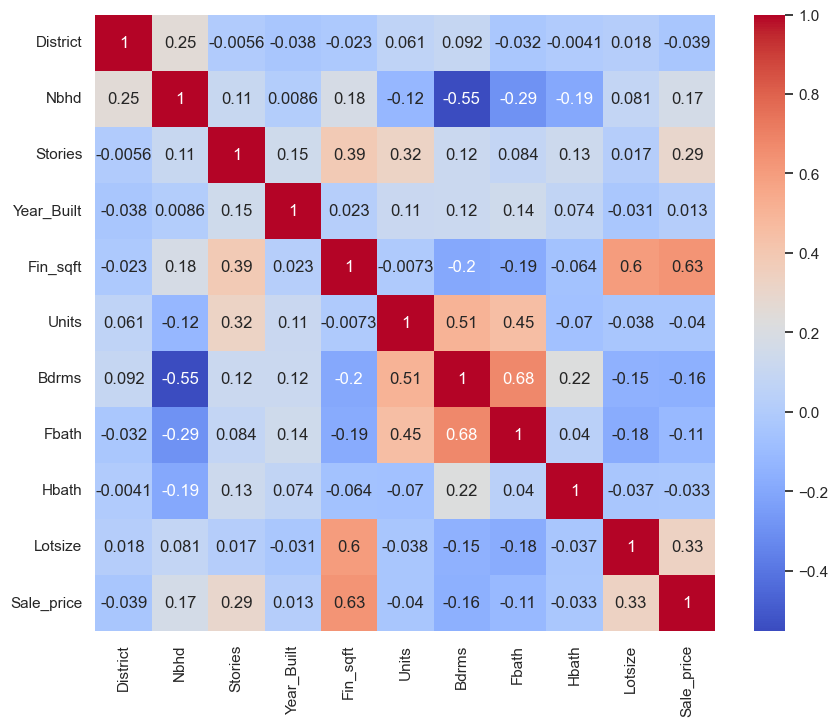

In [112]:
# Plot a heatmap to visualize the correlation matrix of the sample dataframe
plt.figure(figsize=(10, 8))
sns.heatmap(sample_df.corr(),annot=True,cmap="coolwarm")

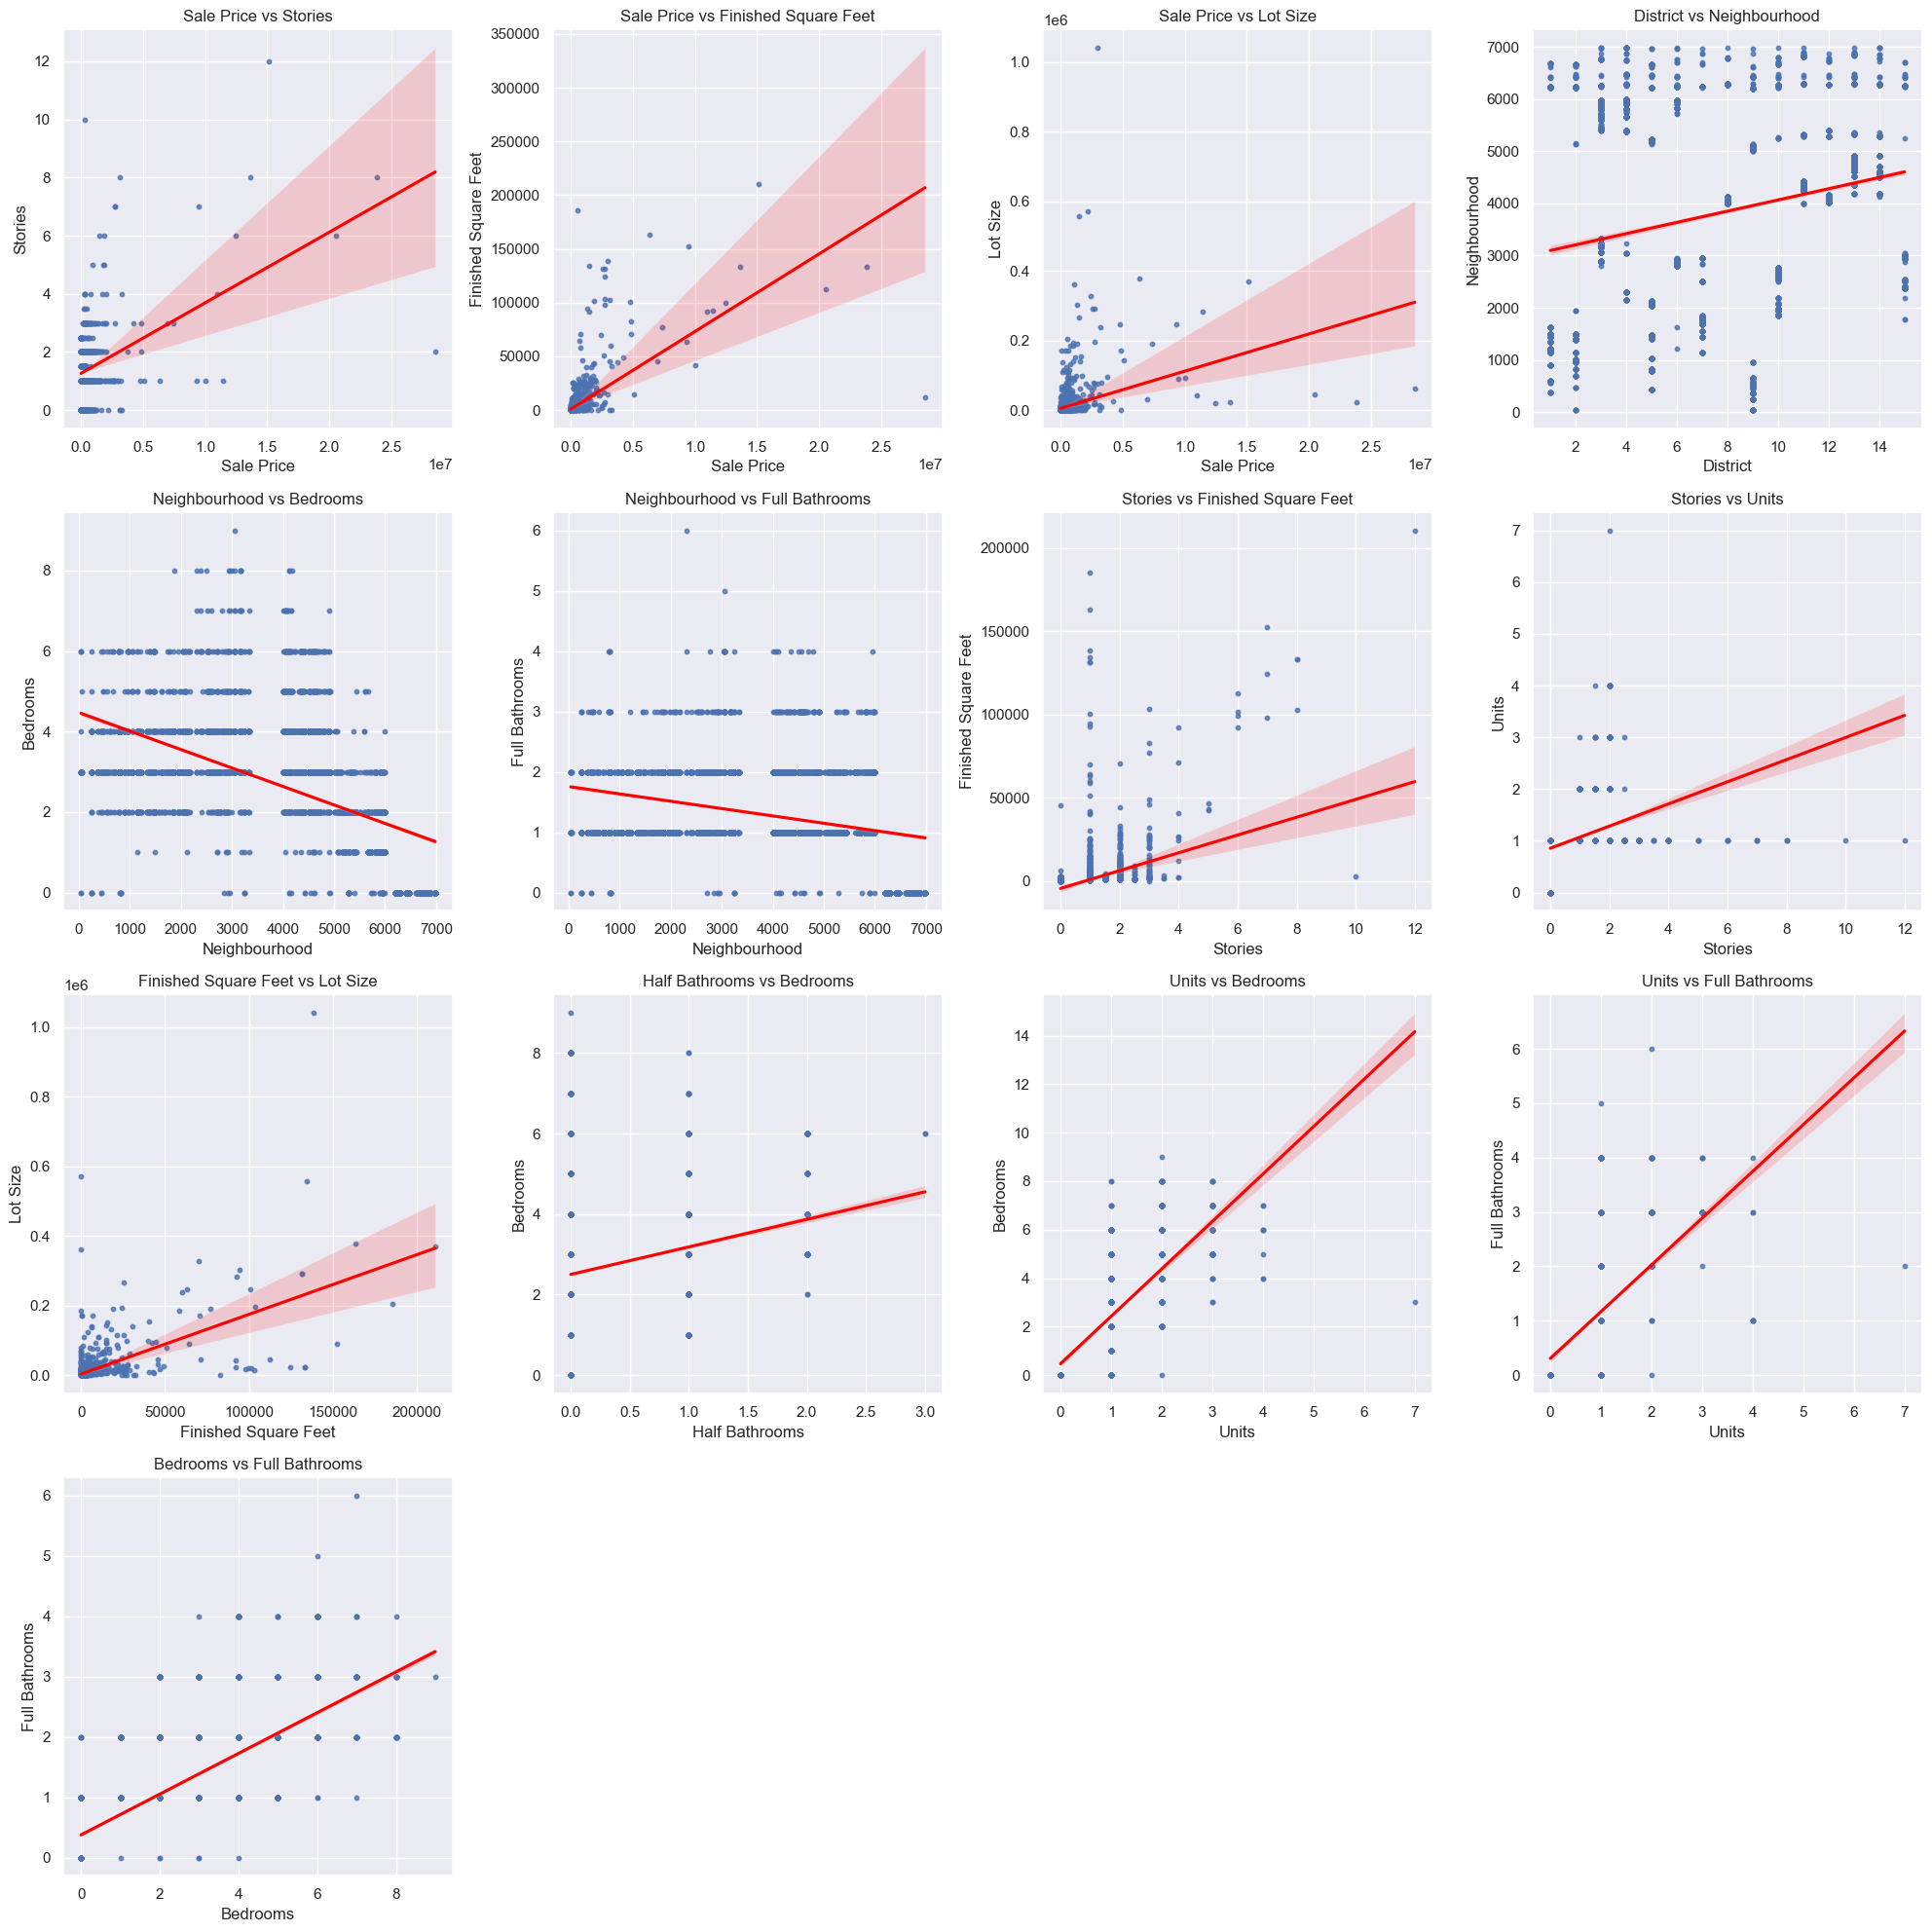

In [113]:
# Define the pairs of columns for the regplots and their corresponding descriptive names
pairs = [
    ('Sale_price', 'Stories', 'Sale Price', 'Stories'),
    ('Sale_price', 'Fin_sqft', 'Sale Price', 'Finished Square Feet'),
    ('Sale_price', 'Lotsize', 'Sale Price', 'Lot Size'),
    ('District', 'Nbhd', 'District', 'Neighbourhood'),
    ('Nbhd', 'Bdrms', 'Neighbourhood', 'Bedrooms'),
    ('Nbhd', 'Fbath', 'Neighbourhood', 'Full Bathrooms'),
    ('Stories', 'Fin_sqft', 'Stories', 'Finished Square Feet'),
    ('Stories', 'Units', 'Stories', 'Units'),
    ('Fin_sqft', 'Lotsize', 'Finished Square Feet', 'Lot Size'),
    ('Hbath', 'Bdrms', 'Half Bathrooms', 'Bedrooms'),
    ('Units', 'Bdrms', 'Units', 'Bedrooms'),
    ('Units', 'Fbath', 'Units', 'Full Bathrooms'),
    ('Bdrms', 'Fbath', 'Bedrooms', 'Full Bathrooms')
]

# Create a 4x4 subplot
fig, axs = plt.subplots(4, 4, figsize=(20, 20))

# Flatten the axes array for easy iteration
axs = axs.flatten()

# Plot each pair in the corresponding subplot
for ax, (x, y, xlabel, ylabel) in zip(axs, pairs):
    sns.regplot(x=x, y=y, data=sample_df, ax=ax, scatter_kws={'s': 10}, line_kws={'color': 'red'})
    ax.set_title(f'{xlabel} vs {ylabel}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

# Hide the last 3 subplots as there are only 13 plots to be shown in a 16 subplot grid
for i in range(len(pairs), len(axs)):
    fig.delaxes(axs[i])

# Adjust layout for better spacing
plt.tight_layout()


# Decision trees

In [114]:
# Prepare the dependent variable matrix X by one-hot encoding categorical features
X = pd.get_dummies(sample_df[['District', 'Style', 'Year_Built', 'Stories']])

# Define the target variable y as the property type
y = sample_df['PropType']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Initialize and train a decision tree classifier on the training data
model = DecisionTreeClassifier()
model.fit(X_train, y_train)

# Predict the target variable (Property type) on the test data
predictions = model.predict(X_test)

# Calculate and print the accuracy score of the model
score = accuracy_score(y_test, predictions)
score

0.9840348330914369

# Logistic regression

In [115]:
# Create a column 'units_to_sqft_ratio' representing the ratio of units to finished square footage
sample_df['units_to_sqft_ratio'] = sample_df['Units'] / sample_df['Fin_sqft']

# Determine the threshold for 'High_Occupancy' as the median of 'units_to_sqft_ratio'
threshold = sample_df['units_to_sqft_ratio'].median()

# Create a binary target variable 'High_Occupancy' based on the threshold
sample_df['High_Occupancy'] = (sample_df['units_to_sqft_ratio'] > threshold).astype(int)

# Select features for the model and define the target variable
features = sample_df[['District', 'Nbhd', 'Bdrms', 'Units', 'Lotsize', 'Fin_sqft']]
target = sample_df['High_Occupancy']

# Define categorical and numerical features for preprocessing
categorical_features = ['District', 'Nbhd']
numerical_features = ['Bdrms', 'Units', 'Lotsize', 'Fin_sqft']

# Create a preprocessor object to scale numerical features and one-hot encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Create a pipeline with the preprocessor and a logistic regression classifier
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', LogisticRegression(max_iter=1000))])

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

# Train the pipeline on the training data
pipeline.fit(X_train, y_train)

# Predict the target variable (High_occupancy) on the test data
y_pred = pipeline.predict(X_test)

# Create and print a classification report to evaluate the model's performance
report = classification_report(y_test, y_pred)
print(report)

# Drop the newly created features from the dataframe to revert to the original state
sample_df.drop("units_to_sqft_ratio",inplace=True,axis=1)
sample_df.drop("High_Occupancy",inplace=True,axis=1)

              precision    recall  f1-score   support

           0       0.94      0.87      0.90       697
           1       0.88      0.94      0.91       681

    accuracy                           0.90      1378
   macro avg       0.91      0.91      0.90      1378
weighted avg       0.91      0.90      0.90      1378



# Linear regression

In [116]:
# Drop the 'Sale_date' column as it is not needed for the regression analysis
sample_df = sample_df.drop(columns=['Sale_date'])

# Replace infinity values with null and then drop all rows with null values
sample_df.replace([np.inf, -np.inf], np.nan, inplace=True)
sample_df = sample_df.dropna()

# Define the categorical and numerical columns
categorical_columns = ['PropType', 'District', 'Nbhd', 'Style', 'Extwall']
numerical_columns = ['Stories', 'Year_Built', 'Fin_sqft', 'Units', 'Bdrms', 'Fbath', 'Hbath', 'Lotsize']

# Use ColumnTransformer to apply OneHotEncoder to categorical columns and passthrough numerical columns
column_transformer = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown='ignore'), categorical_columns),
     ("num", "passthrough", numerical_columns)],
    remainder='passthrough')

# Transform the features using the column transformer
X = column_transformer.fit_transform(sample_df)

# Define the target variable (Sale_price)
y = sample_df['Sale_price']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_linear = linear_model.predict(X_test)

# Calculate the Root Mean Squared Error (RMSE) and R-squared (R^2) score performance metrics
rmse_linear = mean_squared_error(y_test, y_pred_linear, squared=False)
r_squared_linear = r2_score(y_test, y_pred_linear)

# Print the performance metrics to evaluate the linear model
print(f"Linear Regression RMSE: {rmse_linear}")
print(f"Linear Regression R^2: {r_squared_linear}")

Linear Regression RMSE: 0.0005297833800685537
Linear Regression R^2: 1.0


# Cross-validation and ridge regression to avoid overfitting

In [117]:
# Perform cross-validation for Linear Regression
cv_scores_linear = cross_val_score(linear_model, X, y, cv=10, scoring='neg_mean_squared_error')
cv_rmse_linear = np.sqrt(-cv_scores_linear)

# Print the cross-validation RMSE score for Linear Regression
print(f"Cross-validated RMSE (Linear Regression): {cv_rmse_linear.mean()}")

# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_ridge = ridge_model.predict(X_test)

# Calculate the Root Mean Squared Error (RMSE) and R-squared (R^2) score performance metrics
rmse_ridge = mean_squared_error(y_test, y_pred_ridge, squared=False)
r_squared_ridge = r2_score(y_test, y_pred_ridge)

# Print the performance metrics to evaluate the ridge model
print(f"Ridge Regression RMSE: {rmse_ridge}")
print(f"Ridge Regression R^2: {r_squared_ridge}")

# Perform cross-validation for Ridge Regression
cv_scores_ridge = cross_val_score(ridge_model, X, y, cv=10, scoring='neg_mean_squared_error')
cv_rmse_ridge = np.sqrt(-cv_scores_ridge)

# Print the cross-validation RMSE score for Ridge Regression
print(f"Cross-validated RMSE (Ridge Regression): {cv_rmse_ridge.mean()}")

Cross-validated RMSE (Linear Regression): 0.0011972386138878266
Ridge Regression RMSE: 181.51898339065693
Ridge Regression R^2: 0.9999999389603519
Cross-validated RMSE (Ridge Regression): 234.70826369342097
